# Later-stage CRC classification: nested cross-validation

**Comparison:** Healthy vs Stage III/IV  
**Models:** XGBoost and Random Forest  
**Data blocks:** Species, genera and metabolomics

The held-out test set is separated before preprocessing. All filtering, transformation, feature selection and hyperparameter tuning are learned from training data only.


## 1. Imports and reproducibility


In [2]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import (
    SelectKBest,
    f_classif,
    mutual_info_classif,
    VarianceThreshold
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

RANDOM_STATE = 42


/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. File paths


In [3]:
METADATA_PATH = "data/metadata.tsv"
GENERA_PATH = "data/genera.tsv"
SPECIES_ZIP_PATH = "data/species.tsv.zip"
METABOLITE_PATH = "data/mtb.tsv"

## 3. Load the datasets


In [4]:
# Load all data tables
metadata = pd.read_csv(METADATA_PATH, sep="\t")
genera = pd.read_csv(GENERA_PATH, sep="\t")
metabolites = pd.read_csv(METABOLITE_PATH, sep="\t")

with zipfile.ZipFile(SPECIES_ZIP_PATH) as archive:
    species = pd.read_csv(archive.open("species.tsv"), sep="\t")

# Quick shape check
print("Metadata:", metadata.shape)
print("Species:", species.shape)
print("Genera:", genera.shape)
print("Metabolites:", metabolites.shape)

Metadata: (347, 15)
Species: (347, 57703)
Genera: (347, 11943)
Metabolites: (347, 451)


### 3.1 Inspect sample identifiers


In [5]:
for dataframe_name, dataframe in {
    "metadata": metadata,
    "species": species,
    "genera": genera,
    "metabolites": metabolites,
}.items():
    n_samples = dataframe["Sample"].nunique()
    n_duplicates = dataframe["Sample"].duplicated().sum()
    n_missing = dataframe["Sample"].isna().sum()

    print(
        f"{dataframe_name}: {n_samples} unique samples, "
        f"{n_duplicates} duplicates, {n_missing} missing"
    )

metadata: 347 unique samples, 0 duplicates, 0 missing
species: 347 unique samples, 0 duplicates, 0 missing
genera: 347 unique samples, 0 duplicates, 0 missing
metabolites: 347 unique samples, 0 duplicates, 0 missing


### 3.2 Standardize identifier types


In [6]:
metadata["Sample"] = metadata["Sample"].astype(str)
species["Sample"] = species["Sample"].astype(str)
genera["Sample"] = genera["Sample"].astype(str)
metabolites["Sample"] = metabolites["Sample"].astype(str)

## 4. Define the binary outcome


In [7]:
target_groups = ["Healthy", "Stage_III_IV"]

metadata_binary = metadata.loc[
    metadata["Study.Group"].isin(target_groups),
    ["Sample", "Study.Group"],
].copy()

metadata_binary["Label"] = (
    metadata_binary["Study.Group"] == "Stage_III_IV"
).astype(int)


print("Study.Group counts:")
print(metadata_binary["Study.Group"].value_counts())

print("\nEncoded labels (0=Healthy, 1=Stage_III_IV):")
print(metadata_binary["Label"].value_counts().sort_index())

Study.Group counts:
Study.Group
Healthy         127
Stage_III_IV     54
Name: count, dtype: int64

Encoded labels (0=Healthy, 1=Stage_III_IV):
Label
0    127
1     54
Name: count, dtype: int64


### 4.1 Identify participants shared across all omics layers


In [8]:
shared_samples = (
    set(metadata_binary["Sample"])
    & set(species["Sample"])
    & set(genera["Sample"])
    & set(metabolites["Sample"])
)

shared_samples = sorted(shared_samples)

assert len(shared_samples) > 0, "No common samples across all tables"
print("Matched Healthy/Stage III-IV samples:", len(shared_samples))

Matched Healthy/Stage III-IV samples: 181


### 4.2 Create aligned metadata


In [9]:
analysis_metadata = (
    metadata_binary[
        metadata_binary["Sample"].isin(shared_samples)
    ]
    .sort_values("Sample")
    .reset_index(drop=True)
)

print(analysis_metadata.shape)
print(analysis_metadata["Study.Group"].value_counts())

(181, 3)
Study.Group
Healthy         127
Stage_III_IV     54
Name: count, dtype: int64


### 4.3 Align every omics matrix to the same sample order


In [10]:
def align_omics_table(
    dataframe,
    sample_order
):
    aligned = (
        dataframe[
            dataframe["Sample"].isin(sample_order)
        ]
        .set_index("Sample")
        .loc[sample_order]
        .reset_index()
    )

    return aligned


sample_order = analysis_metadata["Sample"].tolist()

species_aligned = align_omics_table(
    species,
    sample_order
)

genera_aligned = align_omics_table(
    genera,
    sample_order
)

metabolites_aligned = align_omics_table(
    metabolites,
    sample_order
)

print("Species aligned:", species_aligned.shape)
print("Genera aligned:", genera_aligned.shape)
print("Metabolites aligned:", metabolites_aligned.shape)

/tmp/ipykernel_3407266/343145041.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()


Species aligned: (181, 57703)
Genera aligned: (181, 11943)
Metabolites aligned: (181, 451)


### 4.4 Verify alignment


In [11]:
assert analysis_metadata["Sample"].tolist() == species_aligned["Sample"].tolist()
assert analysis_metadata["Sample"].tolist() == genera_aligned["Sample"].tolist()
assert analysis_metadata["Sample"].tolist() == metabolites_aligned["Sample"].tolist()

assert analysis_metadata["Sample"].is_unique
assert species_aligned["Sample"].is_unique
assert genera_aligned["Sample"].is_unique
assert metabolites_aligned["Sample"].is_unique

print("All omics layers are correctly aligned.")

All omics layers are correctly aligned.


### 4.5 Construct feature matrices and target


In [12]:
X_species = species_aligned.drop(
    columns="Sample"
).copy()

X_genera = genera_aligned.drop(
    columns="Sample"
).copy()

X_metabolites = metabolites_aligned.drop(
    columns="Sample"
).copy()

y = analysis_metadata["Label"].copy()

print("Species matrix:", X_species.shape)
print("Genera matrix:", X_genera.shape)
print("Metabolite matrix:", X_metabolites.shape)
print("Target:", y.shape)

Species matrix: (181, 57702)
Genera matrix: (181, 11942)
Metabolite matrix: (181, 450)
Target: (181,)


### 4.6 Prefix feature names by data type


In [13]:
X_species.columns = [
    f"species__{column}"
    for column in X_species.columns
]

X_genera.columns = [
    f"genus__{column}"
    for column in X_genera.columns
]

X_metabolites.columns = [
    f"metabolite__{column}"
    for column in X_metabolites.columns
]

print("Species features:", X_species.shape[1])
print("Genus features:", X_genera.shape[1])
print("Metabolite features:", X_metabolites.shape[1])

Species features: 57702
Genus features: 11942
Metabolite features: 450


### 4.7 Validate numeric input


In [14]:
X_species = X_species.apply(
    pd.to_numeric,
    errors="raise"
)

X_genera = X_genera.apply(
    pd.to_numeric,
    errors="raise"
)

X_metabolites = X_metabolites.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Species missing values:", X_species.isna().sum().sum())
print("Genus missing values:", X_genera.isna().sum().sum())
print("Metabolite missing values:", X_metabolites.isna().sum().sum())

assert len(X_species) == len(y)
assert len(X_genera) == len(y)
assert len(X_metabolites) == len(y)

Species missing values: 0
Genus missing values: 0
Metabolite missing values: 0


## 5. Create one shared held-out test set


In [15]:
all_indices = np.arange(
    len(y)
)

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.25,
    stratify=y,
    random_state=RANDOM_STATE
)

y_train = (
    y.iloc[train_indices]
    .reset_index(drop=True)
)

y_test = (
    y.iloc[test_indices]
    .reset_index(drop=True)
)

print("Training samples:", len(y_train))
print("Test samples:", len(y_test))

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTest class counts:")
print(y_test.value_counts())

Training samples: 135
Test samples: 46

Training class counts:
Label
0    95
1    40
Name: count, dtype: int64

Test class counts:
Label
0    32
1    14
Name: count, dtype: int64


### 5.1 Split each omics matrix with the same indices


In [16]:
X_species_train = (
    X_species.iloc[train_indices]
    .reset_index(drop=True)
)

X_species_test = (
    X_species.iloc[test_indices]
    .reset_index(drop=True)
)

X_genera_train = (
    X_genera.iloc[train_indices]
    .reset_index(drop=True)
)

X_genera_test = (
    X_genera.iloc[test_indices]
    .reset_index(drop=True)
)

X_metabolites_train = (
    X_metabolites.iloc[train_indices]
    .reset_index(drop=True)
)

X_metabolites_test = (
    X_metabolites.iloc[test_indices]
    .reset_index(drop=True)
)

print("Species train/test:")
print(X_species_train.shape, X_species_test.shape)

print("\nGenera train/test:")
print(X_genera_train.shape, X_genera_test.shape)

print("\nMetabolites train/test:")
print(X_metabolites_train.shape, X_metabolites_test.shape)

Species train/test:
(135, 57702) (46, 57702)

Genera train/test:
(135, 11942) (46, 11942)

Metabolites train/test:
(135, 450) (46, 450)


### 5.2 Save participant identifiers


In [17]:
train_sample_ids = (
    analysis_metadata
    .iloc[train_indices]["Sample"]
    .reset_index(drop=True)
)

test_sample_ids = (
    analysis_metadata
    .iloc[test_indices]["Sample"]
    .reset_index(drop=True)
)

assert len(train_sample_ids) == len(y_train)
assert len(test_sample_ids) == len(y_test)

print("Training and test sample IDs preserved.")

Training and test sample IDs preserved.


## 6. Leakage-safe preprocessing transformers


In [18]:
class MicrobiomeFilter(
    BaseEstimator,
    TransformerMixin
):
    """
    Remove microbial features with low prevalence
    or very low mean abundance.

    Thresholds are estimated only from training data.
    """

    def __init__(
        self,
        prevalence_threshold=0.10,
        mean_abundance_threshold=1e-5
    ):
        self.prevalence_threshold = prevalence_threshold
        self.mean_abundance_threshold = mean_abundance_threshold

    def fit(
        self,
        X,
        y=None
    ):
        X_df = self._to_dataframe(X)

        prevalence = (
            X_df > 0
        ).mean(axis=0)

        mean_abundance = X_df.mean(axis=0)

        keep_mask = (
            prevalence >= self.prevalence_threshold
        ) & (
            mean_abundance >= self.mean_abundance_threshold
        )

        self.feature_names_in_ = np.asarray(
            X_df.columns,
            dtype=object
        )

        self.selected_features_ = np.asarray(
            X_df.columns[keep_mask],
            dtype=object
        )

        if len(self.selected_features_) == 0:
            raise ValueError(
                "No microbial features passed filtering."
            )

        return self

    def transform(
        self,
        X
    ):
        X_df = self._to_dataframe(X)

        return X_df.loc[
            :,
            self.selected_features_
        ]

    def get_feature_names_out(
        self,
        input_features=None
    ):
        return self.selected_features_

    def _to_dataframe(
        self,
        X
    ):
        if isinstance(X, pd.DataFrame):
            return X.copy()

        if hasattr(
            self,
            "feature_names_in_"
        ):
            return pd.DataFrame(
                X,
                columns=self.feature_names_in_
            )

        return pd.DataFrame(X)

### 6.1 Metabolite missingness filter


In [19]:
class MissingnessFilter(
    BaseEstimator,
    TransformerMixin
):
    """
    Remove features with excessive missing values.

    Missingness is calculated using training data only.
    """

    def __init__(
        self,
        max_missing_fraction=0.30
    ):
        self.max_missing_fraction = max_missing_fraction

    def fit(
        self,
        X,
        y=None
    ):
        X_df = self._to_dataframe(X)

        missing_fraction = (
            X_df.isna().mean(axis=0)
        )

        keep_mask = (
            missing_fraction
            <= self.max_missing_fraction
        )

        self.feature_names_in_ = np.asarray(
            X_df.columns,
            dtype=object
        )

        self.selected_features_ = np.asarray(
            X_df.columns[keep_mask],
            dtype=object
        )

        if len(self.selected_features_) == 0:
            raise ValueError(
                "No metabolite features passed missingness filtering."
            )

        return self

    def transform(
        self,
        X
    ):
        X_df = self._to_dataframe(X)

        return X_df.loc[
            :,
            self.selected_features_
        ]

    def get_feature_names_out(
        self,
        input_features=None
    ):
        return self.selected_features_

    def _to_dataframe(
        self,
        X
    ):
        if isinstance(X, pd.DataFrame):
            return X.copy()

        if hasattr(
            self,
            "feature_names_in_"
        ):
            return pd.DataFrame(
                X,
                columns=self.feature_names_in_
            )

        return pd.DataFrame(X)

### 6.2 Log transformations


In [20]:
class MicrobiomeLogTransformer(
    BaseEstimator,
    TransformerMixin
):
    def __init__(
        self,
        pseudocount=1e-6
    ):
        self.pseudocount = pseudocount

    def fit(
        self,
        X,
        y=None
    ):
        X_array = np.asarray(
            X,
            dtype=float
        )

        if np.any(X_array < 0):
            raise ValueError(
                "Microbiome abundances cannot be negative."
            )

        return self

    def transform(
        self,
        X
    ):
        X_array = np.asarray(
            X,
            dtype=float
        )

        return np.log10(
            X_array + self.pseudocount
        )


class MetaboliteLogTransformer(
    BaseEstimator,
    TransformerMixin
):
    def fit(
        self,
        X,
        y=None
    ):
        X_array = np.asarray(
            X,
            dtype=float
        )

        if np.any(X_array < 0):
            raise ValueError(
                "Negative metabolite values detected."
            )

        return self

    def transform(
        self,
        X
    ):
        return np.log1p(
            np.asarray(
                X,
                dtype=float
            )
        )

## 7. Define the model pipelines

Both classifiers use the same modality-specific preprocessing. The only difference is the final classifier.

- **XGBoost:** primary boosted-tree model.
- **Random Forest:** comparison/baseline ensemble model.


### 7.1 Base classifiers


In [21]:
base_xgb = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=1,
    tree_method="hist"
)


base_rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=1
)


### 7.2 XGBoost pipelines


In [22]:
species_pipeline = Pipeline(
    steps=[
        (
            "microbiome_filter",
            MicrobiomeFilter(
                prevalence_threshold=0.10,
                mean_abundance_threshold=1e-5
            )
        ),
        (
            "log_transform",
            MicrobiomeLogTransformer(
                pseudocount=1e-6
            )
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "select",
            SelectKBest(
                score_func=mutual_info_classif,
                k=50
            )
        ),
        (
            "classifier",
            base_xgb
        )
    ]
)

genera_pipeline = Pipeline(
    steps=[
        (
            "microbiome_filter",
            MicrobiomeFilter(
                prevalence_threshold=0.10,
                mean_abundance_threshold=1e-5
            )
        ),
        (
            "log_transform",
            MicrobiomeLogTransformer(
                pseudocount=1e-6
            )
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "select",
            SelectKBest(
                score_func=mutual_info_classif,
                k=50
            )
        ),
        (
            "classifier",
            base_xgb
        )
    ]
)


In [23]:
metabolite_pipeline = Pipeline(
    steps=[
        (
            "missingness_filter",
            MissingnessFilter(
                max_missing_fraction=0.50
            )
        ),
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "log_transform",
            MetaboliteLogTransformer()
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "select",
            SelectKBest(
                score_func=f_classif,
                k=75
            )
        ),
        (
            "classifier",
            base_xgb
        )
    ]
)


### 7.3 Random Forest pipelines


In [24]:
species_rf_pipeline = Pipeline(
    steps=[
        (
            "microbiome_filter",
            MicrobiomeFilter(
                prevalence_threshold=0.10,
                mean_abundance_threshold=1e-5
            )
        ),
        (
            "log_transform",
            MicrobiomeLogTransformer(
                pseudocount=1e-6
            )
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "select",
            SelectKBest(
                score_func=mutual_info_classif,
                k=50
            )
        ),
        (
            "classifier",
            base_rf
        )
    ]
)

genera_rf_pipeline = Pipeline(
    steps=[
        (
            "microbiome_filter",
            MicrobiomeFilter(
                prevalence_threshold=0.10,
                mean_abundance_threshold=1e-5
            )
        ),
        (
            "log_transform",
            MicrobiomeLogTransformer(
                pseudocount=1e-6
            )
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "select",
            SelectKBest(
                score_func=mutual_info_classif,
                k=50
            )
        ),
        (
            "classifier",
            base_rf
        )
    ]
)


In [25]:
metabolite_rf_pipeline = Pipeline(
    steps=[
        (
            "missingness_filter",
            MissingnessFilter(
                max_missing_fraction=0.50
            )
        ),
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "log_transform",
            MetaboliteLogTransformer()
        ),
        (
            "variance_filter",
            VarianceThreshold(
                threshold=0.0
            )
        ),
        (
            "select",
            SelectKBest(
                score_func=f_classif,
                k=75
            )
        ),
        (
            "classifier",
            base_rf
        )
    ]
)


## 8. Hyperparameter search spaces


### 8.1 XGBoost search spaces


In [84]:
# ============================================================
# Hyperparameter search spaces
# ============================================================

# Species and genus models
microbiome_param_distributions = {
    # Keep the number of selected features conservative because
    # the training set contains only 135 participants.
    "select__k": [5, 10, 15, 20, 30, 50],

    # Restrict tree complexity to reduce memorisation.
    "classifier__max_depth": [1, 2, 3],

    # Number of boosting rounds.
    "classifier__n_estimators": [50, 75, 100, 150],

    # Smaller learning rates generally provide more regularised fits.
    "classifier__learning_rate": [0.01, 0.03, 0.05],

    # Require more observations/effective weight before creating leaves.
    "classifier__min_child_weight": [3, 5, 10],

    # Row subsampling.
    "classifier__subsample": [0.6, 0.7, 0.8],

    # Feature subsampling for each tree.
    "classifier__colsample_bytree": [0.3, 0.5, 0.7],

    # L1 regularisation.
    "classifier__reg_alpha": [0.0, 0.5, 1.0, 2.0, 5.0],

    # L2 regularisation.
    "classifier__reg_lambda": [1.0, 2.0, 5.0, 10.0],

    # ~n_neg/n_pos ≈ 2.375 in full training set
    "classifier__scale_pos_weight": [1, 2, 2.375, 3]  
}


# Separate, more strongly regularised search space
# for the metabolomics model.
metabolite_param_distributions = {
    "select__k": [5, 10, 15, 20, 25, 30],

    "classifier__max_depth": [1, 2],

    "classifier__n_estimators": [50, 75, 100],

    "classifier__learning_rate": [0.01, 0.03, 0.05],

    "classifier__min_child_weight": [5, 10, 15],

    "classifier__subsample": [0.5, 0.6, 0.7, 0.8],

    "classifier__colsample_bytree": [0.3, 0.5, 0.7],

    "classifier__reg_alpha": [1.0, 2.0, 5.0, 10.0],

    "classifier__reg_lambda": [5.0, 10.0, 20.0],
    
    # ~n_neg/n_pos ≈ 2.375 in full training set
    "classifier__scale_pos_weight": [1.0, 2.0, 2.375, 3.0] 
}


### 8.2 Random Forest search spaces


In [27]:
microbiome_rf_param_distributions = {
    "select__k": [5, 10, 15, 20, 30, 50],
    "classifier__n_estimators": [200, 400, 600],
    "classifier__max_depth": [3, 5, 8, None],
    "classifier__min_samples_leaf": [2, 3, 5, 8],
    "classifier__min_samples_split": [4, 6, 10],
    "classifier__max_features": ["sqrt", "log2", 0.3, 0.5],
    "classifier__bootstrap": [True],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}

metabolite_rf_param_distributions = {
    "select__k": [5, 10, 15, 20, 25, 30],
    "classifier__n_estimators": [200, 400, 600],
    "classifier__max_depth": [3, 5, 8, None],
    "classifier__min_samples_leaf": [2, 3, 5, 8],
    "classifier__min_samples_split": [4, 6, 10],
    "classifier__max_features": ["sqrt", "log2", 0.5],
    "classifier__bootstrap": [True],
    "classifier__class_weight": ["balanced", "balanced_subsample"]
}


## 9. Nested cross-validation


The **outer folds** estimate generalization performance. The **inner folds** tune hyperparameters. Only the development/training set enters nested CV.


In [28]:
# ============================================================
# Nested cross-validation setup
# ============================================================

# Inner CV:
# selects hyperparameters inside each outer-training fold.
inner_cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Outer CV:
# estimates generalisation performance.
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE + 1
)


### 9.1 Reusable nested-CV function


In [29]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score


def nested_cv_evaluate(
    pipeline,
    X,
    y,
    model_name,
    param_distributions,
    n_iter=50
):
    """
    Perform nested cross-validation.

    Outer CV:
        Estimates unbiased model performance.

    Inner CV:
        Selects hyperparameters using only the
        outer-training portion.

    Parameters
    ----------
    pipeline : sklearn Pipeline
        Complete preprocessing and classification pipeline.

    X : pandas DataFrame
        Training predictors only.

    y : pandas Series
        Training labels only.

    model_name : str
        Name shown in the printed output.

    param_distributions : dict
        Hyperparameter search space.

    n_iter : int
        Number of random parameter configurations tested
        inside each outer fold.

    Returns
    -------
    results : dict
        Outer-fold scores, selected parameters and
        out-of-fold predictions.
    """

    X = X.reset_index(drop=True)
    y = y.reset_index(drop=True)

    outer_train_scores = []
    outer_validation_scores = []
    best_parameters = []

    # One out-of-fold probability for every training participant.
    oof_probabilities = np.full(
        shape=len(y),
        fill_value=np.nan,
        dtype=float
    )

    for fold_number, (
        outer_train_index,
        outer_validation_index
    ) in enumerate(
        outer_cv.split(X, y),
        start=1
    ):
        print(
            f"\n{model_name} — outer fold "
            f"{fold_number}/{outer_cv.get_n_splits()}"
        )

        X_outer_train = X.iloc[
            outer_train_index
        ].reset_index(drop=True)

        X_outer_validation = X.iloc[
            outer_validation_index
        ].reset_index(drop=True)

        y_outer_train = y.iloc[
            outer_train_index
        ].reset_index(drop=True)

        y_outer_validation = y.iloc[
            outer_validation_index
        ].reset_index(drop=True)

        # A fresh pipeline is used for every outer fold.
        inner_search = RandomizedSearchCV(
            estimator=clone(pipeline),
            param_distributions=param_distributions,
            n_iter=n_iter,
            scoring="roc_auc",
            cv=inner_cv,
            random_state=(
                RANDOM_STATE + fold_number
            ),
            n_jobs=-1,
            verbose=0,
            refit=True,
            return_train_score=True,
            error_score="raise"
        )

        # Hyperparameter selection uses only the
        # outer-training partition.
        inner_search.fit(
            X_outer_train,
            y_outer_train
        )

        best_fold_model = (
            inner_search.best_estimator_
        )

        train_probabilities = (
            best_fold_model.predict_proba(
                X_outer_train
            )[:, 1]
        )

        validation_probabilities = (
            best_fold_model.predict_proba(
                X_outer_validation
            )[:, 1]
        )

        train_auc = roc_auc_score(
            y_outer_train,
            train_probabilities
        )

        validation_auc = roc_auc_score(
            y_outer_validation,
            validation_probabilities
        )

        outer_train_scores.append(
            train_auc
        )

        outer_validation_scores.append(
            validation_auc
        )

        oof_probabilities[
            outer_validation_index
        ] = validation_probabilities

        best_parameters.append(
            inner_search.best_params_
        )

        print(
            "Inner best ROC-AUC:",
            round(
                inner_search.best_score_,
                3
            )
        )

        print(
            "Outer training ROC-AUC:",
            round(train_auc, 3)
        )

        print(
            "Outer validation ROC-AUC:",
            round(validation_auc, 3)
        )

        print(
            "Selected parameters:",
            inner_search.best_params_
        )

    if np.isnan(oof_probabilities).any():
        raise RuntimeError(
            "Some training samples did not receive "
            "out-of-fold predictions."
        )

    overall_oof_auc = roc_auc_score(
        y,
        oof_probabilities
    )

    mean_outer_train_auc = np.mean(
        outer_train_scores
    )

    mean_outer_validation_auc = np.mean(
        outer_validation_scores
    )

    std_outer_validation_auc = np.std(
        outer_validation_scores,
        ddof=1
    )

    nested_gap = (
        mean_outer_train_auc
        - mean_outer_validation_auc
    )

    print("\n" + "=" * 60)
    print(f"{model_name}: nested-CV summary")

    print(
        "Mean outer training ROC-AUC:",
        round(mean_outer_train_auc, 3)
    )

    print(
        "Mean outer validation ROC-AUC:",
        round(
            mean_outer_validation_auc,
            3
        )
    )

    print(
        "Outer validation SD:",
        round(
            std_outer_validation_auc,
            3
        )
    )

    print(
        "Nested train-validation gap:",
        round(nested_gap, 3)
    )

    print(
        "Pooled out-of-fold ROC-AUC:",
        round(overall_oof_auc, 3)
    )

    print(
        "Outer validation scores:",
        np.round(
            outer_validation_scores,
            3
        )
    )

    return {
        "model_name": model_name,
        "outer_train_scores": np.array(
            outer_train_scores
        ),
        "outer_validation_scores": np.array(
            outer_validation_scores
        ),
        "mean_outer_train_auc": (
            mean_outer_train_auc
        ),
        "mean_outer_validation_auc": (
            mean_outer_validation_auc
        ),
        "std_outer_validation_auc": (
            std_outer_validation_auc
        ),
        "train_validation_gap": nested_gap,
        "oof_probabilities": (
            oof_probabilities
        ),
        "oof_auc": overall_oof_auc,
        "best_parameters": best_parameters
    }


### 9.2 XGBoost nested-CV evaluation


In [31]:
species_nested_results = nested_cv_evaluate(
    pipeline=species_pipeline,
    X=X_species_train,
    y=y_train,
    model_name="Species — XGBoost",
    param_distributions=microbiome_param_distributions,
    n_iter=50
)





Species — XGBoost — outer fold 1/5
Inner best ROC-AUC: 0.806
Outer training ROC-AUC: 0.964
Outer validation ROC-AUC: 0.789
Selected parameters: {'select__k': 20, 'classifier__subsample': 0.7, 'classifier__reg_lambda': 10.0, 'classifier__reg_alpha': 0.0, 'classifier__n_estimators': 75, 'classifier__min_child_weight': 3, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.5}

Species — XGBoost — outer fold 2/5
Inner best ROC-AUC: 0.855
Outer training ROC-AUC: 0.964
Outer validation ROC-AUC: 0.763
Selected parameters: {'select__k': 30, 'classifier__subsample': 0.8, 'classifier__reg_lambda': 1.0, 'classifier__reg_alpha': 2.0, 'classifier__n_estimators': 50, 'classifier__min_child_weight': 3, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.3}

Species — XGBoost — outer fold 3/5
Inner best ROC-AUC: 0.842
Outer training ROC-AUC: 0.94
Outer validation ROC-AUC: 0.727
Selected parameters: {'select__k':

In [32]:
genera_nested_results = nested_cv_evaluate(
    pipeline=genera_pipeline,
    X=X_genera_train,
    y=y_train,
    model_name="Genera — XGBoost",
    param_distributions=microbiome_param_distributions,
    n_iter=50
)




Genera — XGBoost — outer fold 1/5
Inner best ROC-AUC: 0.775
Outer training ROC-AUC: 0.907
Outer validation ROC-AUC: 0.888
Selected parameters: {'select__k': 50, 'classifier__subsample': 0.8, 'classifier__reg_lambda': 10.0, 'classifier__reg_alpha': 2.0, 'classifier__n_estimators': 50, 'classifier__min_child_weight': 5, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.5}

Genera — XGBoost — outer fold 2/5
Inner best ROC-AUC: 0.835
Outer training ROC-AUC: 0.947
Outer validation ROC-AUC: 0.697
Selected parameters: {'select__k': 15, 'classifier__subsample': 0.8, 'classifier__reg_lambda': 1.0, 'classifier__reg_alpha': 1.0, 'classifier__n_estimators': 100, 'classifier__min_child_weight': 3, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.7}

Genera — XGBoost — outer fold 3/5
Inner best ROC-AUC: 0.844
Outer training ROC-AUC: 0.892
Outer validation ROC-AUC: 0.766
Selected parameters: {'select__k': 

In [33]:
metabolite_nested_results = nested_cv_evaluate(
    pipeline=metabolite_pipeline,
    X=X_metabolites_train,
    y=y_train,
    model_name="Metabolomics — XGBoost",
    param_distributions=metabolite_param_distributions,
    n_iter=50
)


Metabolomics — XGBoost — outer fold 1/5
Inner best ROC-AUC: 0.64
Outer training ROC-AUC: 0.847
Outer validation ROC-AUC: 0.487
Selected parameters: {'select__k': 20, 'classifier__subsample': 0.5, 'classifier__reg_lambda': 20.0, 'classifier__reg_alpha': 2.0, 'classifier__n_estimators': 50, 'classifier__min_child_weight': 5, 'classifier__max_depth': 1, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.3}

Metabolomics — XGBoost — outer fold 2/5
Inner best ROC-AUC: 0.688
Outer training ROC-AUC: 0.895
Outer validation ROC-AUC: 0.612
Selected parameters: {'select__k': 30, 'classifier__subsample': 0.7, 'classifier__reg_lambda': 5.0, 'classifier__reg_alpha': 1.0, 'classifier__n_estimators': 100, 'classifier__min_child_weight': 5, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.5}

Metabolomics — XGBoost — outer fold 3/5
Inner best ROC-AUC: 0.594
Outer training ROC-AUC: 0.94
Outer validation ROC-AUC: 0.783
Selected parameters

### 9.3 Random Forest nested-CV evaluation


In [34]:
species_rf_nested_results = nested_cv_evaluate(
    pipeline=species_rf_pipeline,
    X=X_species_train,
    y=y_train,
    model_name="Species — Random Forest",
    param_distributions=microbiome_rf_param_distributions,
    n_iter=30
)




Species — Random Forest — outer fold 1/5
Inner best ROC-AUC: 0.789
Outer training ROC-AUC: 0.968
Outer validation ROC-AUC: 0.816
Selected parameters: {'select__k': 10, 'classifier__n_estimators': 400, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 0.3, 'classifier__max_depth': 3, 'classifier__class_weight': 'balanced_subsample', 'classifier__bootstrap': True}

Species — Random Forest — outer fold 2/5
Inner best ROC-AUC: 0.872
Outer training ROC-AUC: 0.994
Outer validation ROC-AUC: 0.743
Selected parameters: {'select__k': 50, 'classifier__n_estimators': 600, 'classifier__min_samples_split': 4, 'classifier__min_samples_leaf': 5, 'classifier__max_features': 'log2', 'classifier__max_depth': 3, 'classifier__class_weight': 'balanced_subsample', 'classifier__bootstrap': True}

Species — Random Forest — outer fold 3/5
Inner best ROC-AUC: 0.878
Outer training ROC-AUC: 0.986
Outer validation ROC-AUC: 0.757
Selected parameters: {'select__k': 3

In [35]:
genera_rf_nested_results = nested_cv_evaluate(
    pipeline=genera_rf_pipeline,
    X=X_genera_train,
    y=y_train,
    model_name="Genera — Random Forest",
    param_distributions=microbiome_rf_param_distributions,
    n_iter=30
)





Genera — Random Forest — outer fold 1/5
Inner best ROC-AUC: 0.724
Outer training ROC-AUC: 0.999
Outer validation ROC-AUC: 0.842
Selected parameters: {'select__k': 50, 'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 3, 'classifier__max_features': 0.3, 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced', 'classifier__bootstrap': True}

Genera — Random Forest — outer fold 2/5
Inner best ROC-AUC: 0.837
Outer training ROC-AUC: 0.956
Outer validation ROC-AUC: 0.809
Selected parameters: {'select__k': 10, 'classifier__n_estimators': 600, 'classifier__min_samples_split': 6, 'classifier__min_samples_leaf': 8, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 8, 'classifier__class_weight': 'balanced_subsample', 'classifier__bootstrap': True}

Genera — Random Forest — outer fold 3/5
Inner best ROC-AUC: 0.845
Outer training ROC-AUC: 0.994
Outer validation ROC-AUC: 0.737
Selected parameters: {'select__k': 50, 'classifie

In [36]:
metabolite_rf_nested_results = nested_cv_evaluate(
    pipeline=metabolite_rf_pipeline,
    X=X_metabolites_train,
    y=y_train,
    model_name="Metabolomics — Random Forest",
    param_distributions=metabolite_rf_param_distributions,
    n_iter=30
)


Metabolomics — Random Forest — outer fold 1/5
Inner best ROC-AUC: 0.671
Outer training ROC-AUC: 0.999
Outer validation ROC-AUC: 0.645
Selected parameters: {'select__k': 25, 'classifier__n_estimators': 200, 'classifier__min_samples_split': 4, 'classifier__min_samples_leaf': 3, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced', 'classifier__bootstrap': True}

Metabolomics — Random Forest — outer fold 2/5
Inner best ROC-AUC: 0.694
Outer training ROC-AUC: 1.0
Outer validation ROC-AUC: 0.579
Selected parameters: {'select__k': 30, 'classifier__n_estimators': 600, 'classifier__min_samples_split': 6, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 5, 'classifier__class_weight': 'balanced_subsample', 'classifier__bootstrap': True}

Metabolomics — Random Forest — outer fold 3/5
Inner best ROC-AUC: 0.691
Outer training ROC-AUC: 0.998
Outer validation ROC-AUC: 0.836
Selected parameters: {'select__

### 9.4 Compare nested-CV performance


In [37]:
nested_cv_results = pd.DataFrame([
    {
        "Modality": "Species",
        "Model": "XGBoost",
        "Mean_outer_AUC": species_nested_results["mean_outer_validation_auc"],
        "Outer_AUC_SD": species_nested_results["std_outer_validation_auc"],
        "Train_validation_gap": species_nested_results["train_validation_gap"]
    },
    {
        "Modality": "Species",
        "Model": "Random Forest",
        "Mean_outer_AUC": species_rf_nested_results["mean_outer_validation_auc"],
        "Outer_AUC_SD": species_rf_nested_results["std_outer_validation_auc"],
        "Train_validation_gap": species_rf_nested_results["train_validation_gap"]
    },
    {
        "Modality": "Genera",
        "Model": "XGBoost",
        "Mean_outer_AUC": genera_nested_results["mean_outer_validation_auc"],
        "Outer_AUC_SD": genera_nested_results["std_outer_validation_auc"],
        "Train_validation_gap": genera_nested_results["train_validation_gap"]
    },
    {
        "Modality": "Genera",
        "Model": "Random Forest",
        "Mean_outer_AUC": genera_rf_nested_results["mean_outer_validation_auc"],
        "Outer_AUC_SD": genera_rf_nested_results["std_outer_validation_auc"],
        "Train_validation_gap": genera_rf_nested_results["train_validation_gap"]
    },
    {
        "Modality": "Metabolomics",
        "Model": "XGBoost",
        "Mean_outer_AUC": metabolite_nested_results["mean_outer_validation_auc"],
        "Outer_AUC_SD": metabolite_nested_results["std_outer_validation_auc"],
        "Train_validation_gap": metabolite_nested_results["train_validation_gap"]
    },
    {
        "Modality": "Metabolomics",
        "Model": "Random Forest",
        "Mean_outer_AUC": metabolite_rf_nested_results["mean_outer_validation_auc"],
        "Outer_AUC_SD": metabolite_rf_nested_results["std_outer_validation_auc"],
        "Train_validation_gap": metabolite_rf_nested_results["train_validation_gap"]
    }
])

nested_cv_results.round(3)


,Modality,Model,Mean_outer_AUC,Outer_AUC_SD,Train_validation_gap
0,Species,XGBoost,0.774,0.038,0.178
1,Species,Random Forest,0.783,0.043,0.203
2,Genera,XGBoost,0.801,0.082,0.104
3,Genera,Random Forest,0.809,0.053,0.172
4,Metabolomics,XGBoost,0.649,0.136,0.241
5,Metabolomics,Random Forest,0.695,0.096,0.297


## 10. Fit final tuned models on the complete training set

Nested CV above provides the primary generalization estimate. The searches below select one final fitted model per modality and classifier using the complete development set. The held-out test set remains untouched.


In [38]:
def fit_final_search(
    pipeline,
    param_distributions,
    X_train,
    y_train,
    n_iter=50
):
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring="roc_auc",
        cv=inner_cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        verbose=1,
        error_score="raise"
    )
    search.fit(X_train, y_train)
    return search


### 10.1 Final XGBoost models


In [39]:
species_search = fit_final_search(
    species_pipeline,
    microbiome_param_distributions,
    X_species_train,
    y_train,
    n_iter=50
)

genera_search = fit_final_search(
    genera_pipeline,
    microbiome_param_distributions,
    X_genera_train,
    y_train,
    n_iter=50
)

metabolite_search = fit_final_search(
    metabolite_pipeline,
    metabolite_param_distributions,
    X_metabolites_train,
    y_train,
    n_iter=50
)


Fitting 4 folds for each of 50 candidates, totalling 200 fits
Fitting 4 folds for each of 50 candidates, totalling 200 fits
Fitting 4 folds for each of 50 candidates, totalling 200 fits


### 10.2 Final Random Forest models


In [40]:
species_rf_search = fit_final_search(
    species_rf_pipeline,
    microbiome_rf_param_distributions,
    X_species_train,
    y_train,
    n_iter=30
)

genera_rf_search = fit_final_search(
    genera_rf_pipeline,
    microbiome_rf_param_distributions,
    X_genera_train,
    y_train,
    n_iter=30
)

metabolite_rf_search = fit_final_search(
    metabolite_rf_pipeline,
    metabolite_rf_param_distributions,
    X_metabolites_train,
    y_train,
    n_iter=30
)


Fitting 4 folds for each of 30 candidates, totalling 120 fits
Fitting 4 folds for each of 30 candidates, totalling 120 fits
Fitting 4 folds for each of 30 candidates, totalling 120 fits


## 11. Predict once on the held-out test set


In [41]:
# XGBoost probabilities
species_test_probability = species_search.best_estimator_.predict_proba(
    X_species_test
)[:, 1]

genera_test_probability = genera_search.best_estimator_.predict_proba(
    X_genera_test
)[:, 1]

metabolite_test_probability = metabolite_search.best_estimator_.predict_proba(
    X_metabolites_test
)[:, 1]

# Random Forest probabilities
species_rf_test_probability = species_rf_search.best_estimator_.predict_proba(
    X_species_test
)[:, 1]

genera_rf_test_probability = genera_rf_search.best_estimator_.predict_proba(
    X_genera_test
)[:, 1]

metabolite_rf_test_probability = metabolite_rf_search.best_estimator_.predict_proba(
    X_metabolites_test
)[:, 1]


## 12. XGBoost late integration

Late integration is retained for the XGBoost models only. Weights are derived from nested-CV performance on the training set, not from the test set.


In [42]:
species_cv_auc = species_nested_results[
    "mean_outer_validation_auc"
]

genera_cv_auc = genera_nested_results[
    "mean_outer_validation_auc"
]

metabolite_cv_auc = metabolite_nested_results[
    "mean_outer_validation_auc"
]

species_weight = (
    species_cv_auc
    / (species_cv_auc + metabolite_cv_auc)
)

species_metabolite_weight = (
    metabolite_cv_auc
    / (species_cv_auc + metabolite_cv_auc)
)

genera_weight = (
    genera_cv_auc
    / (genera_cv_auc + metabolite_cv_auc)
)

genera_metabolite_weight = (
    metabolite_cv_auc
    / (genera_cv_auc + metabolite_cv_auc)
)

print(
    "Species + metabolomics weights:",
    round(species_weight, 3),
    round(species_metabolite_weight, 3)
)

print(
    "Genera + metabolomics weights:",
    round(genera_weight, 3),
    round(genera_metabolite_weight, 3)
)

Species + metabolomics weights: 0.544 0.456
Genera + metabolomics weights: 0.552 0.448


In [43]:
species_metabolite_probability = (
    species_weight
    * species_test_probability
    +
    species_metabolite_weight
    * metabolite_test_probability
)

genera_metabolite_probability = (
    genera_weight
    * genera_test_probability
    +
    genera_metabolite_weight
    * metabolite_test_probability
)

In [44]:
species_metabolite_auc = roc_auc_score(
    y_test,
    species_metabolite_probability
)

genera_metabolite_auc = roc_auc_score(
    y_test,
    genera_metabolite_probability
)

print(
    "Species + metabolomics test ROC-AUC:",
    round(species_metabolite_auc, 3)
)

print(
    "Genus + metabolomics test ROC-AUC:",
    round(genera_metabolite_auc, 3)
)

Species + metabolomics test ROC-AUC: 0.661
Genus + metabolomics test ROC-AUC: 0.703


## 13. Held-out test evaluation


In [45]:
def bootstrap_auc_ci(
    y_true,
    probabilities,
    n_bootstraps=2000,
    confidence_level=0.95,
    random_state=RANDOM_STATE
):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    rng = np.random.default_rng(
        random_state
    )

    bootstrap_scores = []

    for _ in range(n_bootstraps):
        bootstrap_indices = rng.integers(
            0,
            len(y_true),
            len(y_true)
        )

        y_bootstrap = y_true[
            bootstrap_indices
        ]

        probability_bootstrap = probabilities[
            bootstrap_indices
        ]

        if len(np.unique(y_bootstrap)) < 2:
            continue

        bootstrap_scores.append(
            roc_auc_score(
                y_bootstrap,
                probability_bootstrap
            )
        )

    alpha = (
        1 - confidence_level
    ) / 2

    lower = np.quantile(
        bootstrap_scores,
        alpha
    )

    upper = np.quantile(
        bootstrap_scores,
        1 - alpha
    )

    return lower, upper



def evaluate_probabilities(
    y_true,
    probabilities,
    model_name,
    threshold=0.50
):
    """Calculate probability- and threshold-based binary metrics."""
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    predictions = (probabilities >= threshold).astype(int)

    roc_auc = roc_auc_score(y_true, probabilities)
    pr_auc = average_precision_score(y_true, probabilities)
    accuracy = accuracy_score(y_true, predictions)
    precision = precision_score(y_true, predictions, zero_division=0)
    sensitivity = recall_score(y_true, predictions, zero_division=0)
    f1 = f1_score(y_true, predictions, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    ci_lower, ci_upper = bootstrap_auc_ci(y_true, probabilities)

    return {
        "Model": model_name,
        "Threshold": threshold,
        "ROC_AUC": roc_auc,
        "ROC_AUC_CI_Lower": ci_lower,
        "ROC_AUC_CI_Upper": ci_upper,
        "PR_AUC": pr_auc,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall_Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


### 13.1 Metrics table

`Recall` and `sensitivity` are the same metric, so they are reported as one column. The classification threshold is fixed at 0.50 and is not optimized on the test set.


In [46]:
results = [
    evaluate_probabilities(
        y_test, species_test_probability, "Species — XGBoost"
    ),
    evaluate_probabilities(
        y_test, species_rf_test_probability, "Species — Random Forest"
    ),
    evaluate_probabilities(
        y_test, genera_test_probability, "Genera — XGBoost"
    ),
    evaluate_probabilities(
        y_test, genera_rf_test_probability, "Genera — Random Forest"
    ),
    evaluate_probabilities(
        y_test, metabolite_test_probability, "Metabolomics — XGBoost"
    ),
    evaluate_probabilities(
        y_test, metabolite_rf_test_probability, "Metabolomics — Random Forest"
    ),
    evaluate_probabilities(
        y_test,
        species_metabolite_probability,
        "Species + Metabolomics — XGBoost late integration"
    ),
    evaluate_probabilities(
        y_test,
        genera_metabolite_probability,
        "Genera + Metabolomics — XGBoost late integration"
    )
]

results_df = (
    pd.DataFrame(results)
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

display_columns = [
    "Model",
    "ROC_AUC",
    "ROC_AUC_CI_Lower",
    "ROC_AUC_CI_Upper",
    "PR_AUC",
    "Accuracy",
    "Precision",
    "Recall_Sensitivity",
    "Specificity",
    "F1_Score"
]

results_df[display_columns].round(3)


,Model,ROC_AUC,ROC_AUC_CI_Lower,ROC_AUC_CI_Upper,PR_AUC,Accuracy,Precision,Recall_Sensitivity,Specificity,F1_Score
0,Species — Random Forest,0.828,0.701,0.937,0.600,0.761,0.615,0.571,0.844,0.593
1,Genera — Random Forest,0.799,0.654,0.920,0.660,0.783,0.625,0.714,0.812,0.667
2,Species — XGBoost,0.787,0.635,0.910,0.601,0.696,0.000,0.000,1.000,0.000
3,Genera — XGBoost,0.766,0.611,0.901,0.562,0.696,0.000,0.000,1.000,0.000
4,Genera + Metabolomics — XGBoost late integration,0.703,0.520,0.863,0.540,0.696,0.000,0.000,1.000,0.000
5,Metabolomics — Random Forest,0.661,0.475,0.823,0.453,0.630,0.364,0.286,0.781,0.320
6,Species + Metabolomics — XGBoost late integration,0.661,0.468,0.833,0.523,0.696,0.000,0.000,1.000,0.000
7,Metabolomics — XGBoost,0.612,0.418,0.774,0.447,0.696,0.500,0.143,0.938,0.222


### 13.2 ROC and precision–recall curves


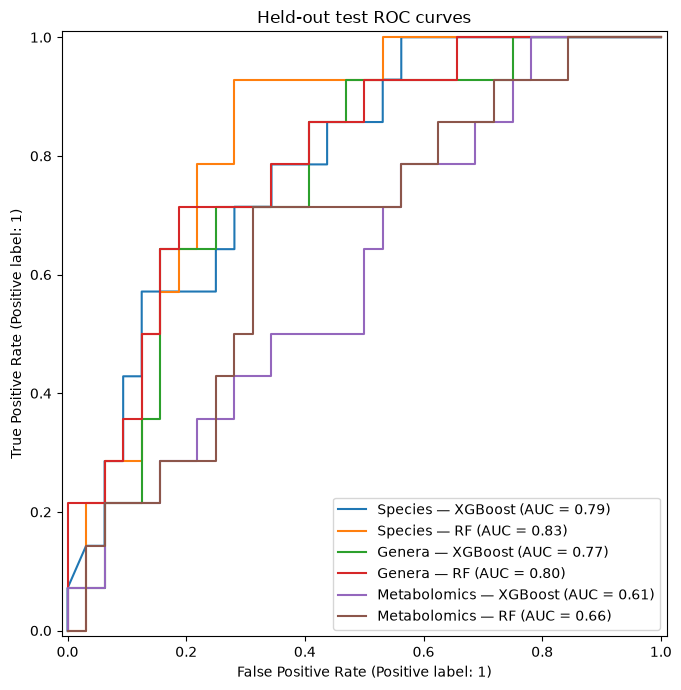

In [47]:
fig, ax = plt.subplots(figsize=(9, 7))

probability_sets = {
    "Species — XGBoost": species_test_probability,
    "Species — RF": species_rf_test_probability,
    "Genera — XGBoost": genera_test_probability,
    "Genera — RF": genera_rf_test_probability,
    "Metabolomics — XGBoost": metabolite_test_probability,
    "Metabolomics — RF": metabolite_rf_test_probability
}

for name, probabilities in probability_sets.items():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=ax
    )

ax.set_title("Held-out test ROC curves")
plt.tight_layout()
plt.show()


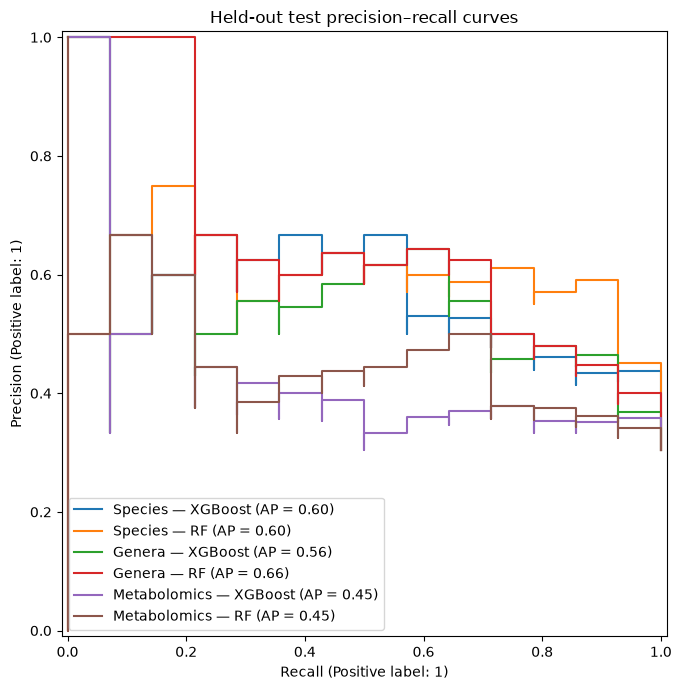

In [48]:
fig, ax = plt.subplots(figsize=(9, 7))

for name, probabilities in probability_sets.items():
    PrecisionRecallDisplay.from_predictions(
        y_test,
        probabilities,
        name=name,
        ax=ax
    )

ax.set_title("Held-out test precision–recall curves")
plt.tight_layout()
plt.show()


## 14. XGBoost SHAP interpretation

SHAP is reported for the final XGBoost models only. Training data are used for interpretation so the held-out test set remains dedicated to final performance assessment.


In [49]:
# Check the binary class encoding
print("XGBoost classes:", species_search.best_estimator_
      .named_steps["classifier"].classes_)

print("\nTraining class counts:")
print(pd.Series(y_train).value_counts().sort_index())

XGBoost classes: [0 1]

Training class counts:
Label
0    95
1    40
Name: count, dtype: int64


In [50]:
label_mapping = {
    0: "Healthy",
    1: "Stage III/IV"
}

print(label_mapping)

{0: 'Healthy', 1: 'Stage III/IV'}


In [51]:
def parse_taxonomy_feature(feature_name):
    """
    Extract family, genus and species from a taxonomy
    feature name.

    Example:
    species__d__Bacteria;...;f__Marinifilaceae;
    g__Odoribacter;s__Odoribacter sp905193145
    """

    taxonomy = str(feature_name)

    # Remove feature-level prefix
    taxonomy = taxonomy.replace(
        "species__",
        ""
    ).replace(
        "genus__",
        ""
    )

    taxonomy_parts = taxonomy.split(";")

    taxonomy_dict = {}

    for part in taxonomy_parts:
        if "__" in part:
            rank, taxon = part.split(
                "__",
                1
            )

            taxonomy_dict[rank] = taxon

    family = taxonomy_dict.get(
        "f",
        "Unclassified family"
    )

    genus = taxonomy_dict.get(
        "g",
        "Unclassified genus"
    )

    species = taxonomy_dict.get(
        "s",
        "Unclassified species"
    )

    return family, genus, species

In [52]:
parse_taxonomy_feature(
    X_species_train.columns[0]
)

('Marinifilaceae', 'Odoribacter', 'Odoribacter sp905193145')

### 14.1 Species model


In [53]:
species_best_pipeline = (
    species_search.best_estimator_
)

species_preprocessor = (
    species_best_pipeline[:-1]
)

species_model = (
    species_best_pipeline
    .named_steps["classifier"]
)

In [54]:
# Use training data for model interpretation.
# The test set remains reserved for final performance evaluation.
X_species_train_transformed = (
    species_preprocessor.transform(
        X_species_train
    )
)

if hasattr(
    X_species_train_transformed,
    "toarray"
):
    X_species_train_transformed = (
        X_species_train_transformed.toarray()
    )

print(
    "Transformed species training shape:",
    X_species_train_transformed.shape
)

Transformed species training shape: (135, 10)


In [55]:
# Features remaining after prevalence filtering
species_filtered_features = np.asarray(
    species_best_pipeline
    .named_steps["microbiome_filter"]
    .get_feature_names_out(
        X_species_train.columns
    )
)

# Features remaining after variance filtering
species_variance_mask = (
    species_best_pipeline
    .named_steps["variance_filter"]
    .get_support()
)

species_after_variance = (
    species_filtered_features[
        species_variance_mask
    ]
)

# Features remaining after SelectKBest
species_selection_mask = (
    species_best_pipeline
    .named_steps["select"]
    .get_support()
)

species_selected_features = (
    species_after_variance[
        species_selection_mask
    ]
)

print(
    "Selected species features:",
    len(species_selected_features)
)

Selected species features: 10


In [56]:
species_taxonomy = pd.DataFrame(
    [
        parse_taxonomy_feature(feature)
        for feature in species_selected_features
    ],
    columns=[
        "Family",
        "Genus",
        "Species"
    ]
)

species_taxonomy["Original_Feature"] = (
    species_selected_features
)

species_taxonomy.head()

,Family,Genus,Species,Original_Feature
0,Fusobacteriaceae,Fusobacterium,Fusobacterium nucleatum_J,species__d__Bacteria;p__Fusobacteriota;c__Fuso...
1,Peptoniphilaceae,Parvimonas,Parvimonas micra,species__d__Bacteria;p__Firmicutes_A;c__Clostr...
2,Muribaculaceae,CAG-1031,CAG-1031 sp900752535,species__d__Bacteria;p__Bacteroidota;c__Bacter...
3,Peptostreptococcaceae,Peptostreptococcus,Peptostreptococcus stomatis,species__d__Bacteria;p__Firmicutes_A;c__Clostr...
4,Gemellaceae,Gemella,Gemella morbillorum,species__d__Bacteria;p__Firmicutes;c__Bacilli;...


In [57]:
species_display_names = (
    species_taxonomy["Genus"].astype(str)
    + " | "
    + species_taxonomy["Species"].astype(str)
).to_numpy()

In [58]:
# Alternative label containing all three ranks
species_full_display_names = (
    species_taxonomy["Family"].astype(str)
    + " | "
    + species_taxonomy["Genus"].astype(str)
    + " | "
    + species_taxonomy["Species"].astype(str)
).to_numpy()

In [59]:
if (
    X_species_train_transformed.shape[1]
    != len(species_display_names)
):
    raise ValueError(
        "Species feature-name mismatch: "
        f"{X_species_train_transformed.shape[1]} "
        "transformed columns versus "
        f"{len(species_display_names)} names."
    )

In [60]:
X_species_shap = pd.DataFrame(
    X_species_train_transformed,
    columns=species_display_names,
    index=X_species_train.index
)

In [61]:
species_explainer = shap.TreeExplainer(
    species_model
)

species_shap_values = species_explainer(
    X_species_shap
)

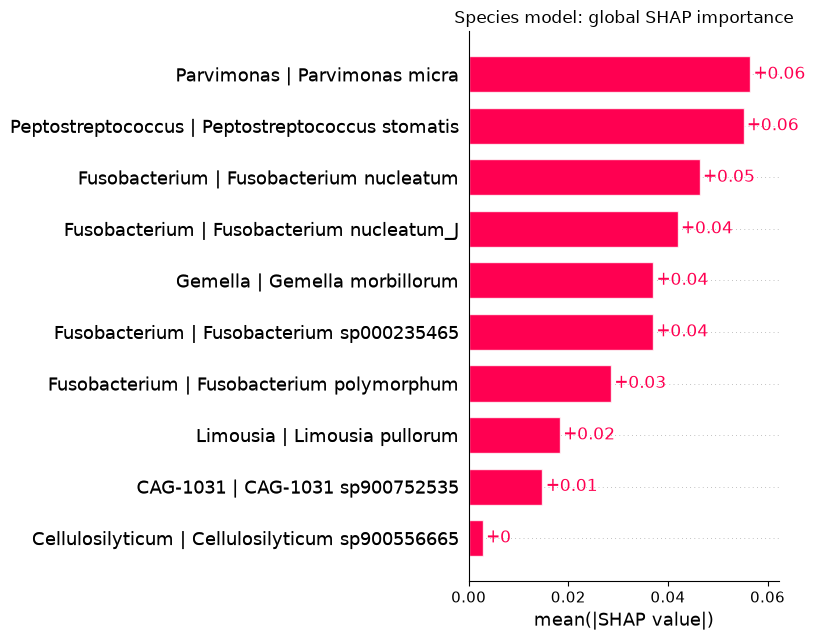

In [62]:
shap.plots.bar(
    species_shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Species model: global SHAP importance"
)

plt.tight_layout()
plt.show()

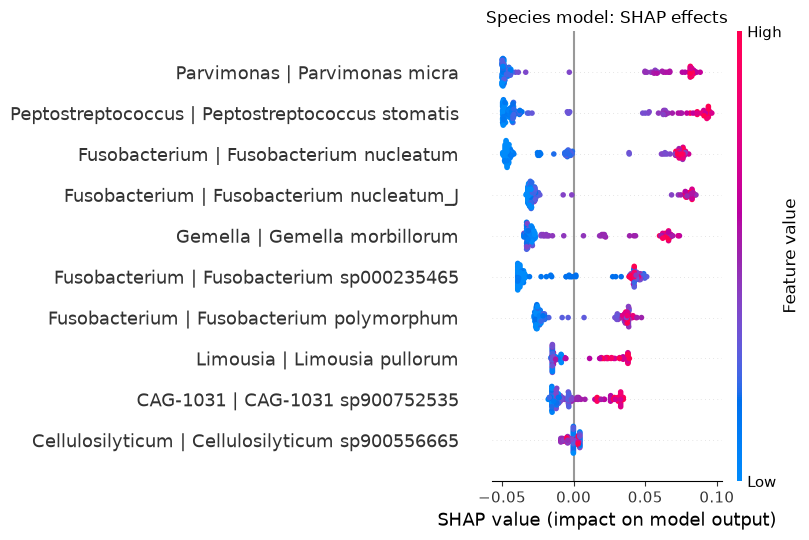

In [63]:
shap.plots.beeswarm(
    species_shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Species model: SHAP effects"
)

plt.tight_layout()
plt.show()

In [64]:
species_shap_importance = pd.DataFrame({
    "Family": species_taxonomy["Family"],
    "Genus": species_taxonomy["Genus"],
    "Species": species_taxonomy["Species"],
    "Original_Feature": (
        species_taxonomy["Original_Feature"]
    ),
    "Mean_abs_SHAP": np.abs(
        species_shap_values.values
    ).mean(axis=0)
})

species_shap_importance = (
    species_shap_importance
    .sort_values(
        "Mean_abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

species_shap_importance.head(20)

,Family,Genus,Species,Original_Feature,Mean_abs_SHAP
0,Peptoniphilaceae,Parvimonas,Parvimonas micra,species__d__Bacteria;p__Firmicutes_A;c__Clostr...,0.056513
1,Peptostreptococcaceae,Peptostreptococcus,Peptostreptococcus stomatis,species__d__Bacteria;p__Firmicutes_A;c__Clostr...,0.055178
2,Fusobacteriaceae,Fusobacterium,Fusobacterium nucleatum,species__d__Bacteria;p__Fusobacteriota;c__Fuso...,0.046381
3,Fusobacteriaceae,Fusobacterium,Fusobacterium nucleatum_J,species__d__Bacteria;p__Fusobacteriota;c__Fuso...,0.041961
4,Gemellaceae,Gemella,Gemella morbillorum,species__d__Bacteria;p__Firmicutes;c__Bacilli;...,0.037045
5,Fusobacteriaceae,Fusobacterium,Fusobacterium sp000235465,species__d__Bacteria;p__Fusobacteriota;c__Fuso...,0.037008
6,Fusobacteriaceae,Fusobacterium,Fusobacterium polymorphum,species__d__Bacteria;p__Fusobacteriota;c__Fuso...,0.028571
7,Acutalibacteraceae,Limousia,Limousia pullorum,species__d__Bacteria;p__Firmicutes_A;c__Clostr...,0.018307
8,Muribaculaceae,CAG-1031,CAG-1031 sp900752535,species__d__Bacteria;p__Bacteroidota;c__Bacter...,0.014820
9,Cellulosilyticaceae,Cellulosilyticum,Cellulosilyticum sp900556665,species__d__Bacteria;p__Firmicutes_A;c__Clostr...,0.002835


### 14.2 Genera model


In [65]:
genera_best_pipeline = (
    genera_search.best_estimator_
)

genera_preprocessor = (
    genera_best_pipeline[:-1]
)

genera_model = (
    genera_best_pipeline
    .named_steps["classifier"]
)

X_genera_train_transformed = (
    genera_preprocessor.transform(
        X_genera_train
    )
)

if hasattr(
    X_genera_train_transformed,
    "toarray"
):
    X_genera_train_transformed = (
        X_genera_train_transformed.toarray()
    )

In [66]:
genera_filtered_features = np.asarray(
    genera_best_pipeline
    .named_steps["microbiome_filter"]
    .get_feature_names_out(
        X_genera_train.columns
    )
)

genera_variance_mask = (
    genera_best_pipeline
    .named_steps["variance_filter"]
    .get_support()
)

genera_after_variance = (
    genera_filtered_features[
        genera_variance_mask
    ]
)

genera_selection_mask = (
    genera_best_pipeline
    .named_steps["select"]
    .get_support()
)

genera_selected_features = (
    genera_after_variance[
        genera_selection_mask
    ]
)

print(
    "Selected genera features:",
    len(genera_selected_features)
)

Selected genera features: 15


In [67]:
genera_taxonomy = pd.DataFrame(
    [
        parse_taxonomy_feature(feature)
        for feature in genera_selected_features
    ],
    columns=[
        "Family",
        "Genus",
        "Species"
    ]
)

genera_taxonomy["Original_Feature"] = (
    genera_selected_features
)

genera_display_names = (
    genera_taxonomy["Family"].astype(str)
    + " | "
    + genera_taxonomy["Genus"].astype(str)
).to_numpy()

In [68]:
if (
    X_genera_train_transformed.shape[1]
    != len(genera_display_names)
):
    raise ValueError(
        "Genera feature-name mismatch."
    )

X_genera_shap = pd.DataFrame(
    X_genera_train_transformed,
    columns=genera_display_names,
    index=X_genera_train.index
)

In [69]:
genera_explainer = shap.TreeExplainer(
    genera_model
)

genera_shap_values = genera_explainer(
    X_genera_shap
)

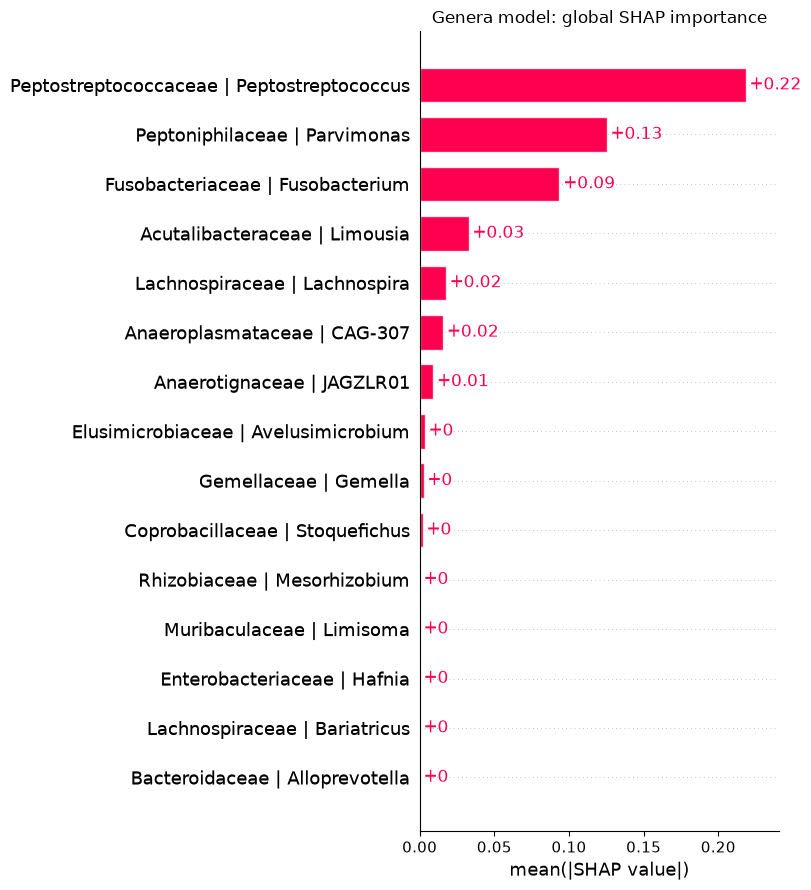

In [70]:
shap.plots.bar(
    genera_shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Genera model: global SHAP importance"
)

plt.tight_layout()
plt.show()

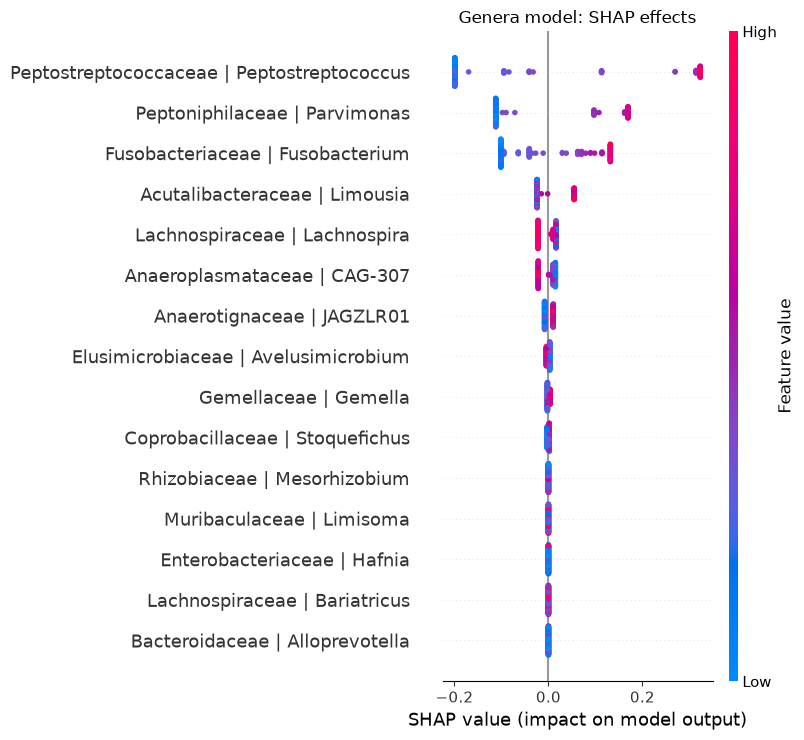

In [71]:
shap.plots.beeswarm(
    genera_shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Genera model: SHAP effects"
)

plt.tight_layout()
plt.show()

In [72]:
genera_shap_importance = pd.DataFrame({
    "Family": genera_taxonomy["Family"],
    "Genus": genera_taxonomy["Genus"],
    "Original_Feature": (
        genera_taxonomy["Original_Feature"]
    ),
    "Mean_abs_SHAP": np.abs(
        genera_shap_values.values
    ).mean(axis=0)
})

genera_shap_importance = (
    genera_shap_importance
    .sort_values(
        "Mean_abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

genera_shap_importance.head(20)

,Family,Genus,Original_Feature,Mean_abs_SHAP
0,Peptostreptococcaceae,Peptostreptococcus,genus__d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.218280
1,Peptoniphilaceae,Parvimonas,genus__d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.125229
2,Fusobacteriaceae,Fusobacterium,genus__d__Bacteria;p__Fusobacteriota;c__Fusoba...,0.093576
3,Acutalibacteraceae,Limousia,genus__d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.032752
4,Lachnospiraceae,Lachnospira,genus__d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.017521
5,Anaeroplasmataceae,CAG-307,genus__d__Bacteria;p__Firmicutes;c__Bacilli;o_...,0.015643
6,Anaerotignaceae,JAGZLR01,genus__d__Bacteria;p__Firmicutes_A;c__Clostrid...,0.009058
7,Elusimicrobiaceae,Avelusimicrobium,genus__d__Bacteria;p__Elusimicrobiota;c__Elusi...,0.003348
8,Gemellaceae,Gemella,genus__d__Bacteria;p__Firmicutes;c__Bacilli;o_...,0.002594
9,Coprobacillaceae,Stoquefichus,genus__d__Bacteria;p__Firmicutes;c__Bacilli;o_...,0.001990


### 14.3 Metabolomics model


In [73]:
metabolite_best_pipeline = (
    metabolite_search.best_estimator_
)

metabolite_preprocessor = (
    metabolite_best_pipeline[:-1]
)

metabolite_model = (
    metabolite_best_pipeline
    .named_steps["classifier"]
)

X_metabolites_train_transformed = (
    metabolite_preprocessor.transform(
        X_metabolites_train
    )
)

if hasattr(
    X_metabolites_train_transformed,
    "toarray"
):
    X_metabolites_train_transformed = (
        X_metabolites_train_transformed.toarray()
    )

In [74]:
metabolite_filtered_features = np.asarray(
    metabolite_best_pipeline
    .named_steps["missingness_filter"]
    .get_feature_names_out(
        X_metabolites_train.columns
    )
)

metabolite_variance_mask = (
    metabolite_best_pipeline
    .named_steps["variance_filter"]
    .get_support()
)

metabolite_after_variance = (
    metabolite_filtered_features[
        metabolite_variance_mask
    ]
)

metabolite_selection_mask = (
    metabolite_best_pipeline
    .named_steps["select"]
    .get_support()
)

metabolite_selected_features = (
    metabolite_after_variance[
        metabolite_selection_mask
    ]
)

print(
    "Selected metabolite features:",
    len(metabolite_selected_features)
)

Selected metabolite features: 15


In [75]:
if (
    X_metabolites_train_transformed.shape[1]
    != len(metabolite_selected_features)
):
    raise ValueError(
        "Metabolomics feature-name mismatch."
    )

X_metabolites_shap = pd.DataFrame(
    X_metabolites_train_transformed,
    columns=metabolite_selected_features,
    index=X_metabolites_train.index
)

In [76]:
metabolite_explainer = shap.TreeExplainer(
    metabolite_model
)

metabolite_shap_values = (
    metabolite_explainer(
        X_metabolites_shap
    )
)

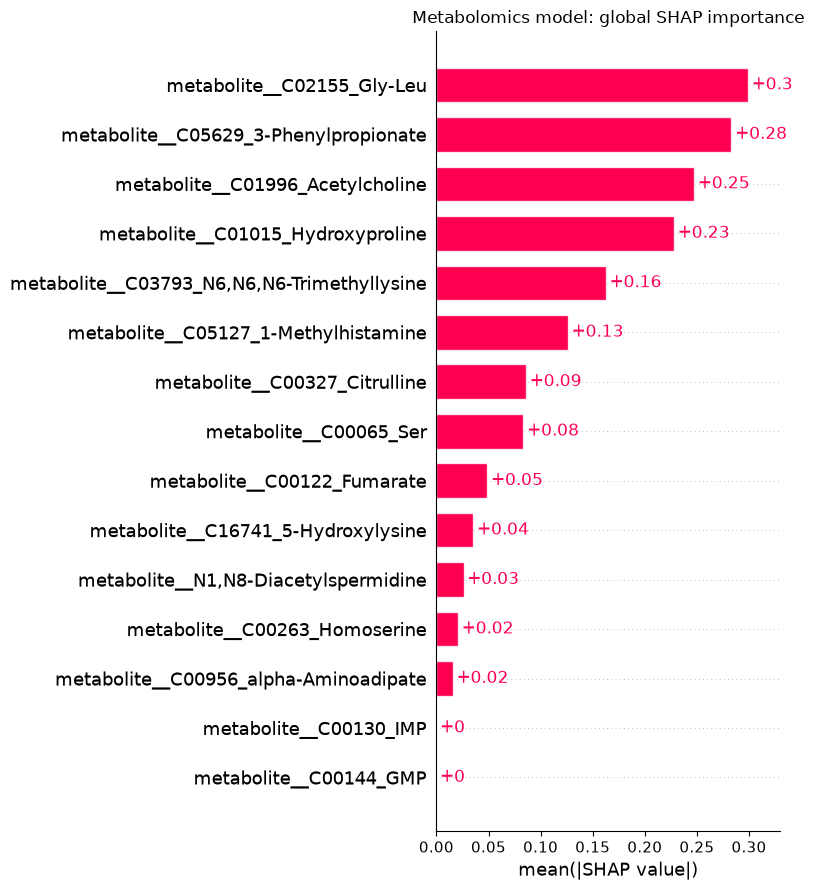

In [77]:
shap.plots.bar(
    metabolite_shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Metabolomics model: global SHAP importance"
)

plt.tight_layout()
plt.show()

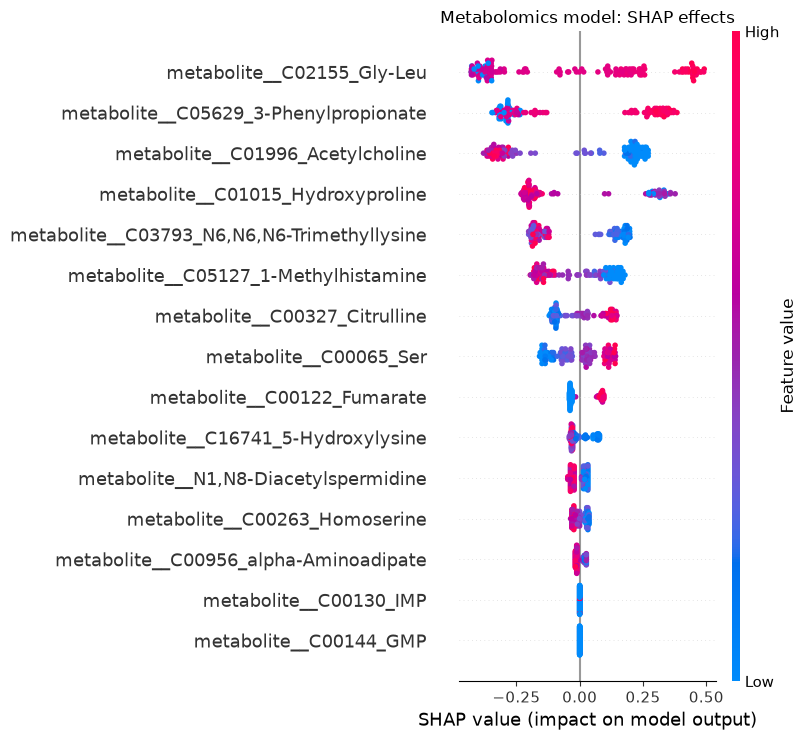

In [78]:
shap.plots.beeswarm(
    metabolite_shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Metabolomics model: SHAP effects"
)

plt.tight_layout()
plt.show()

In [79]:
metabolite_shap_importance = pd.DataFrame({
    "Metabolite": (
        metabolite_selected_features
    ),
    "Mean_abs_SHAP": np.abs(
        metabolite_shap_values.values
    ).mean(axis=0)
})

metabolite_shap_importance = (
    metabolite_shap_importance
    .sort_values(
        "Mean_abs_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

metabolite_shap_importance.head(20)

,Metabolite,Mean_abs_SHAP
0,metabolite__C02155_Gly-Leu,0.299091
1,metabolite__C05629_3-Phenylpropionate,0.283189
2,metabolite__C01996_Acetylcholine,0.247384
3,metabolite__C01015_Hydroxyproline,0.228066
4,"metabolite__C03793_N6,N6,N6-Trimethyllysine",0.162678
5,metabolite__C05127_1-Methylhistamine,0.126227
6,metabolite__C00327_Citrulline,0.086011
7,metabolite__C00065_Ser,0.083520
8,metabolite__C00122_Fumarate,0.048895
9,metabolite__C16741_5-Hydroxylysine,0.035474


In [80]:
species_shap_importance.to_csv(
    "later_stage_species_shap.csv",
    index=False
)

genera_shap_importance.to_csv(
    "later_stage_genera_shap.csv",
    index=False
)

metabolite_shap_importance.to_csv(
    "later_stage_metabolomics_shap.csv",
    index=False
)

print("SHAP importance tables saved.")

SHAP importance tables saved.


## 15. Reporting notes

- Use nested-CV mean ROC-AUC ± SD as the primary model-comparison result.
- Report the held-out test metrics as one final evaluation.
- Do not select a model or threshold repeatedly based on test-set performance.
- State that recall and sensitivity are equivalent.
- Late integration in this notebook uses the XGBoost unimodal predictions.
